# 06 — Four-Model Comparative Analysis

With ARIMA, Prophet, LightGBM, and TimesFM all trained, this notebook brings them together: overall metrics, per-country performance, forecast overlays, error distributions, speed, and — most usefully — a practical answer to "which model should I actually use, and when?"

**Prerequisite:** run Notebooks 01, 02, 04, and 05 first.

**Walkthrough:**
1. Load all results
2. Overall metrics comparison
3. Per-country performance
4. Forecast overlay visualization
5. Residual & error distribution
6. Speed & efficiency analysis
7. Model ranking & trade-offs
8. Export comparison report


## Loading all results


In [1]:
# Cell 1: Setup and load
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

plt.style.use('seaborn-v0_8-whitegrid')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
RESULTS_DIR = f'{DRIVE_BASE}/Comparison_Results_4Model'
os.makedirs(RESULTS_DIR, exist_ok=True)

# All 4 model result files
MODEL_FILES = {
    'ARIMA': f'{DRIVE_BASE}/ARIMA_Results/arima_results.json',
    'Prophet': f'{DRIVE_BASE}/Prophet_Results/prophet_results.json',
    'LightGBM': f'{DRIVE_BASE}/LightGBM_Results/lightgbm_results.json',
    'TimesFM': f'{DRIVE_BASE}/TimesFM_Results/timesfm_results.json',
}

# Model display colors (consistent across all plots)
MODEL_COLORS = {
    'ARIMA': '#9C27B0',       # Purple
    'Prophet': '#2196F3',     # Blue
    'LightGBM': '#4CAF50',   # Green
    'TimesFM': '#FF9800',    # Orange
}

results = {}
for name, path in MODEL_FILES.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            results[name] = json.load(f)
        print(f'  ✓ Loaded: {name}')
    else:
        print(f'  ✗ NOT FOUND: {name} ({path})')

print(f'\nModels loaded: {list(results.keys())} ({len(results)}/4)')
assert len(results) == 4, 'All 4 model results required. Run Notebooks 01,02,04,05 first.'

# Get country list
countries = results['Prophet']['dataset']['countries']

Mounted at /content/drive
  ✓ Loaded: ARIMA
  ✓ Loaded: Prophet
  ✓ Loaded: LightGBM
  ✓ Loaded: TimesFM

Models loaded: ['ARIMA', 'Prophet', 'LightGBM', 'TimesFM'] (4/4)


## Overall metrics, side by side

All four models scored against the same test set.


In [2]:
# Cell 2: Build comparison DataFrame
metrics_data = []
for model_name, res in results.items():
    m = res['metrics']['overall']
    metrics_data.append({
        'Model': model_name,
        'MAE (EUR)': m['mae'],
        'RMSE (EUR)': m['rmse'],
        'MAPE (%)': m['mape'],
        'SMAPE (%)': m['smape'],
        'Time (s)': res['training']['total_time_seconds'],
    })

comparison_df = pd.DataFrame(metrics_data).set_index('Model')

# Sort by MAE (best first)
comparison_df = comparison_df.sort_values('MAE (EUR)')

print('=' * 70)
print('OVERALL METRICS COMPARISON (sorted by MAE)')
print('=' * 70)
print(comparison_df.round(2).to_string())

# Winner per metric
print('\n--- Winner per Metric (lower is better) ---')
for col in comparison_df.columns:
    winner = comparison_df[col].idxmin()
    best_val = comparison_df[col].min()
    worst_val = comparison_df[col].max()
    pct_gap = ((worst_val - best_val) / worst_val) * 100
    print(f'  {col:<12}: {winner} ({best_val:.2f}) — '
          f'{pct_gap:.1f}% better than worst')

OVERALL METRICS COMPARISON (sorted by MAE)
          MAE (EUR)  RMSE (EUR)  MAPE (%)  SMAPE (%)  Time (s)
Model                                                         
Prophet     1092.77     1507.09      7.40       7.30      2.14
TimesFM     1496.45     2185.28      9.11       9.29      2.64
ARIMA       2840.43     3833.99     16.90      19.27     60.27
LightGBM    3468.40     4427.93     23.24      21.08      0.08

--- Winner per Metric (lower is better) ---
  MAE (EUR)   : Prophet (1092.77) — 68.5% better than worst
  RMSE (EUR)  : Prophet (1507.09) — 66.0% better than worst
  MAPE (%)    : Prophet (7.40) — 68.2% better than worst
  SMAPE (%)   : Prophet (7.30) — 65.4% better than worst
  Time (s)    : LightGBM (0.08) — 99.9% better than worst


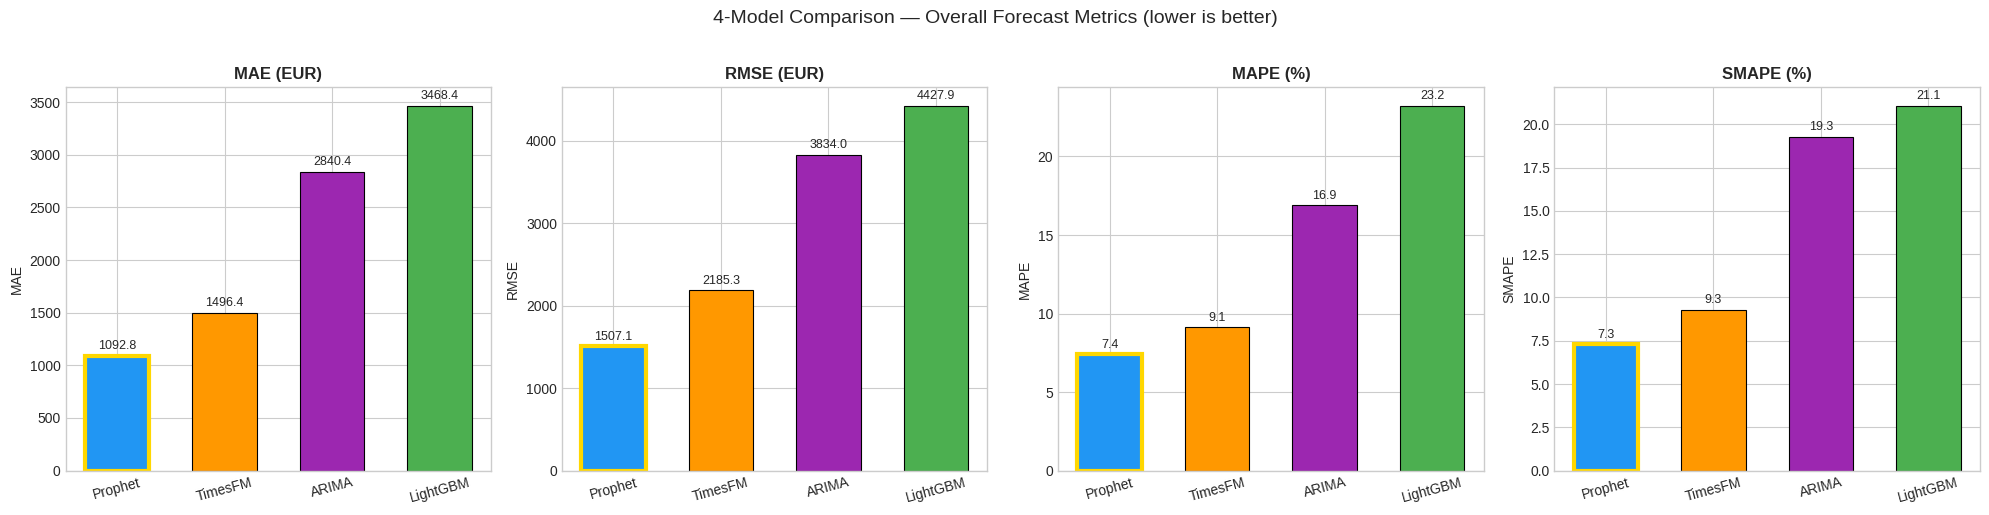

Metrics chart saved.


In [3]:
# Cell 3: Overall metrics bar chart (4 models)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
metrics_to_plot = ['MAE (EUR)', 'RMSE (EUR)', 'MAPE (%)', 'SMAPE (%)']

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    models = comparison_df.index.tolist()
    values = comparison_df[metric].values
    colors = [MODEL_COLORS[m] for m in models]

    bars = ax.bar(models, values, color=colors, edgecolor='black',
                  linewidth=0.8, width=0.6)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric.split('(')[0].strip())

    # Value labels
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01 * max(values),
                f'{val:.1f}', ha='center', va='bottom', fontsize=9)

    # Highlight winner
    winner_idx = np.argmin(values)
    bars[winner_idx].set_edgecolor('gold')
    bars[winner_idx].set_linewidth(3)

    ax.tick_params(axis='x', rotation=15)

plt.suptitle('4-Model Comparison — Overall Forecast Metrics (lower is better)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_metrics.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Metrics chart saved.')

## Per-country performance

Which model wins in each country? This is where it gets interesting — market maturity and series length seem to favor different models.


In [4]:
# Cell 4: Per-country comparison table
country_comparison = []
for country in countries:
    row = {'Country': country}
    maes = {}
    for model_name in results:
        mae = results[model_name]['metrics']['per_country'][country]['mae']
        mape = results[model_name]['metrics']['per_country'][country]['mape']
        row[f'{model_name} MAE'] = mae
        row[f'{model_name} MAPE'] = mape
        maes[model_name] = mae
    row['MAE Winner'] = min(maes, key=maes.get)
    country_comparison.append(row)

country_df = pd.DataFrame(country_comparison)
print('=== Per-Country MAE Comparison ===')
mae_cols = ['Country'] + [f'{m} MAE' for m in results] + ['MAE Winner']
print(country_df[mae_cols].to_string(index=False, float_format='{:.0f}'.format))

# Win counts
print('\n--- MAE Win Count ---')
wins = country_df['MAE Winner'].value_counts()
for model, count in wins.items():
    print(f'  {model}: {count} countries')

=== Per-Country MAE Comparison ===
Country  ARIMA MAE  Prophet MAE  LightGBM MAE  TimesFM MAE MAE Winner
     BE       1873          726          2140         1024    Prophet
     DE       3095         1152          4907         2433    Prophet
     ES       2318         1154          3731         1252    Prophet
     FR       4484         1155          4430         1865    Prophet
     IT       5142         1017          2246         1492    Prophet
     NL       1910         1086          3846          934    TimesFM
     PT       1473          961          1563          876    TimesFM
     UK       2430         1491          4884         2096    Prophet

--- MAE Win Count ---
  Prophet: 6 countries
  TimesFM: 2 countries


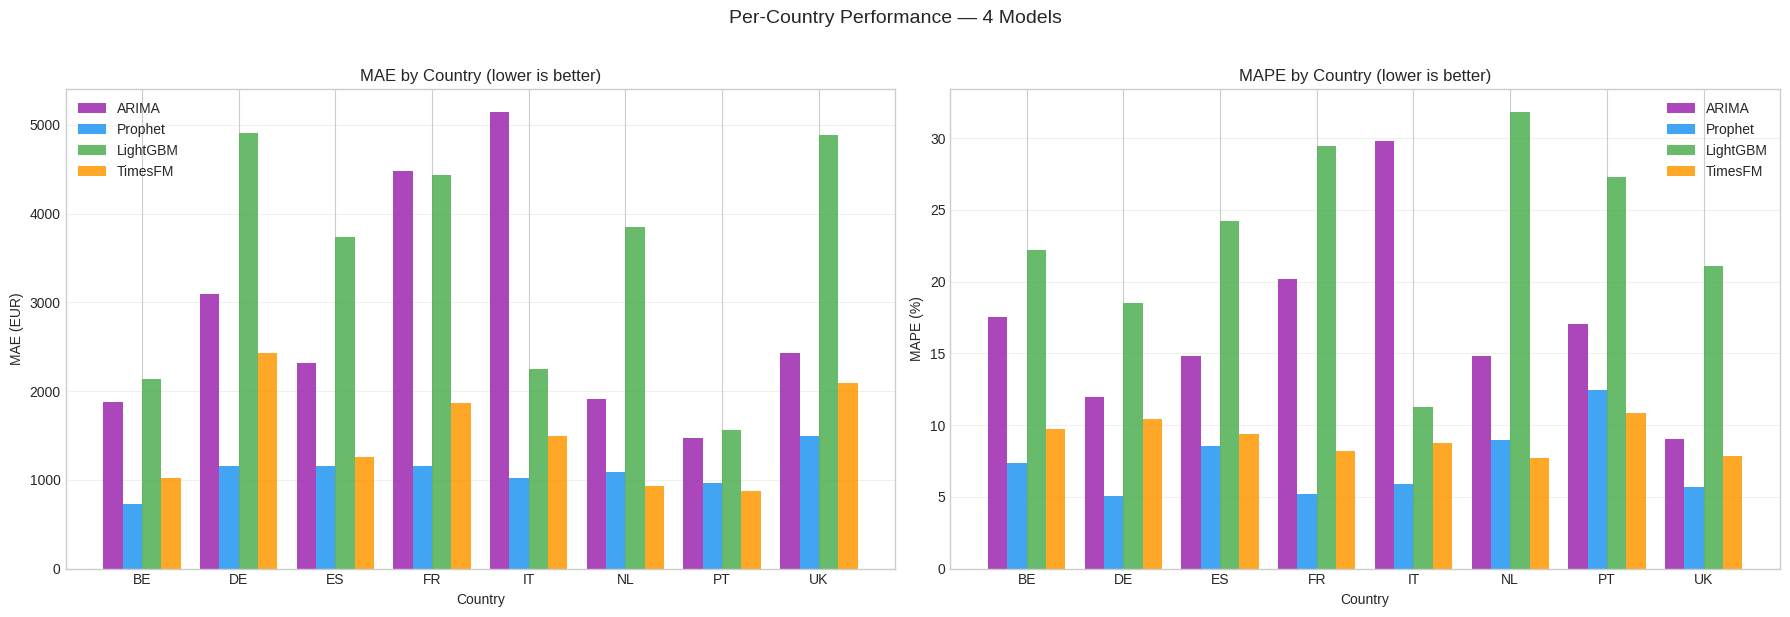

Per-country chart saved.


In [5]:
# Cell 5: Per-country grouped bar chart
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

x = np.arange(len(countries))
width = 0.2
model_names = list(results.keys())

# MAE bars
for i, model in enumerate(model_names):
    maes = [results[model]['metrics']['per_country'][c]['mae'] for c in countries]
    axes[0].bar(x + i * width - 1.5 * width, maes, width,
               label=model, color=MODEL_COLORS[model], alpha=0.85)

axes[0].set_xlabel('Country')
axes[0].set_ylabel('MAE (EUR)')
axes[0].set_title('MAE by Country (lower is better)', fontsize=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(countries)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# MAPE bars
for i, model in enumerate(model_names):
    mapes = [results[model]['metrics']['per_country'][c]['mape'] for c in countries]
    axes[1].bar(x + i * width - 1.5 * width, mapes, width,
               label=model, color=MODEL_COLORS[model], alpha=0.85)

axes[1].set_xlabel('Country')
axes[1].set_ylabel('MAPE (%)')
axes[1].set_title('MAPE by Country (lower is better)', fontsize=12)
axes[1].set_xticks(x)
axes[1].set_xticklabels(countries)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Per-Country Performance — 4 Models', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_per_country.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Per-country chart saved.')

## Forecast overlay

All four models' predictions plotted against actuals, per country.


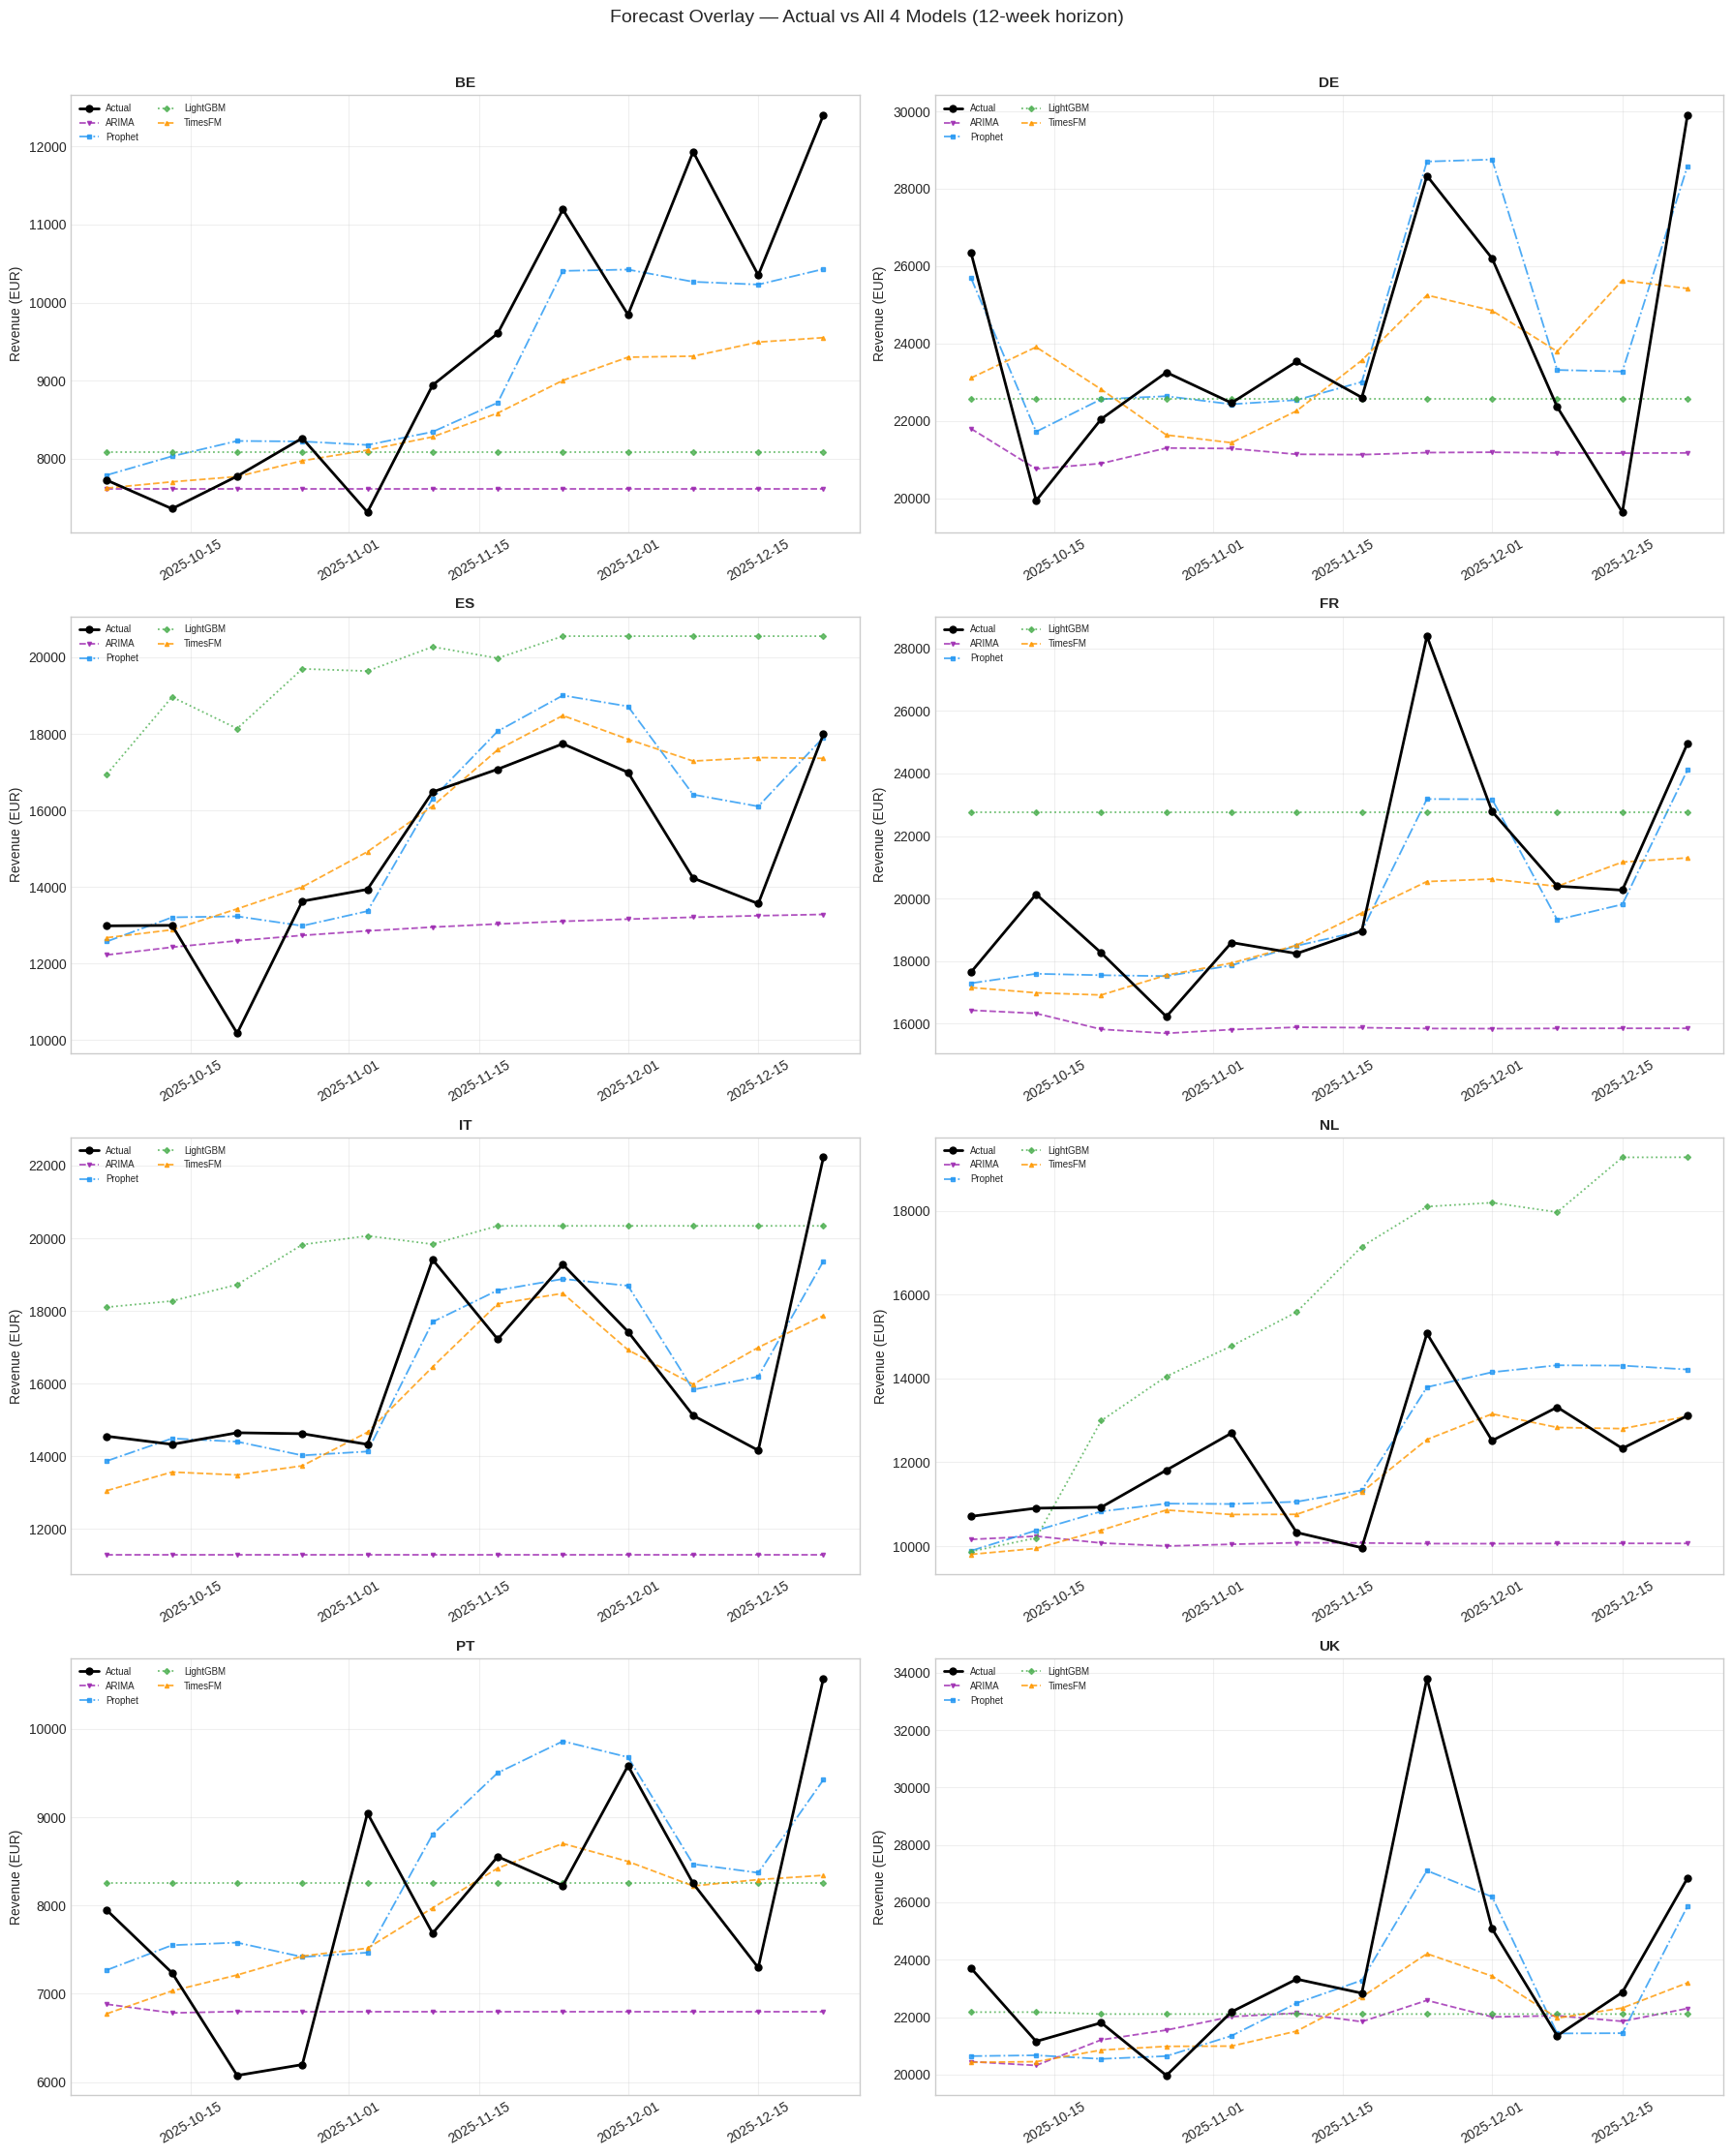

Forecast overlay saved.


In [6]:
# Cell 6: Forecast overlay — all 4 models
fig, axes = plt.subplots(4, 2, figsize=(18, 22))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]

    # Get dates from Prophet (all models share same test dates)
    dates = pd.to_datetime(results['Prophet']['forecasts'][country]['dates'])
    actual = results['Prophet']['forecasts'][country]['actual']

    # Plot actual
    ax.plot(dates, actual, 'k-o', linewidth=2, markersize=5,
            label='Actual', zorder=5)

    # Plot each model
    line_styles = {'ARIMA': '--', 'Prophet': '-.',
                   'LightGBM': ':', 'TimesFM': '--'}
    markers = {'ARIMA': 'v', 'Prophet': 's',
               'LightGBM': 'D', 'TimesFM': '^'}

    for model_name in results:
        predicted = results[model_name]['forecasts'][country]['predicted']
        ax.plot(dates, predicted,
                linestyle=line_styles[model_name],
                marker=markers[model_name],
                color=MODEL_COLORS[model_name],
                linewidth=1.3, markersize=3, alpha=0.8,
                label=model_name)

    ax.set_title(f'{country}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle(
    'Forecast Overlay — Actual vs All 4 Models (12-week horizon)',
    fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_forecast_overlay.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Forecast overlay saved.')

## Residual & error distribution

How errors are distributed across all four models.


In [7]:
# Cell 7: Collect residuals for all models
all_residuals = {}
for model_name in results:
    residuals = []
    for country in countries:
        f = results[model_name]['forecasts'][country]
        actual = np.array(f['actual'])
        predicted = np.array(f['predicted'])
        residuals.extend(actual - predicted)
    all_residuals[model_name] = np.array(residuals)

# Residual stats table
print('=== Residual Statistics ===')
print(f'{"Model":<12} {"Mean":>10} {"Median":>10} {"Std":>10} {"Bias":>10}')
print('-' * 55)
for model_name, resid in all_residuals.items():
    print(f'{model_name:<12} {np.mean(resid):>10.2f} '
          f'{np.median(resid):>10.2f} {np.std(resid):>10.2f} '
          f'{"Low" if abs(np.mean(resid)) < 200 else "HIGH":>10}')

=== Residual Statistics ===
Model              Mean     Median        Std       Bias
-------------------------------------------------------
ARIMA           2652.30    2255.86    2768.53       HIGH
Prophet           40.42      37.89    1506.54        Low
LightGBM        -379.50    -458.23    4411.63       HIGH
TimesFM          568.40     495.92    2110.06       HIGH


/tmp/ipykernel_1564/3629847443.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=resid_df, x='Model', y='Residual', ax=axes[1],


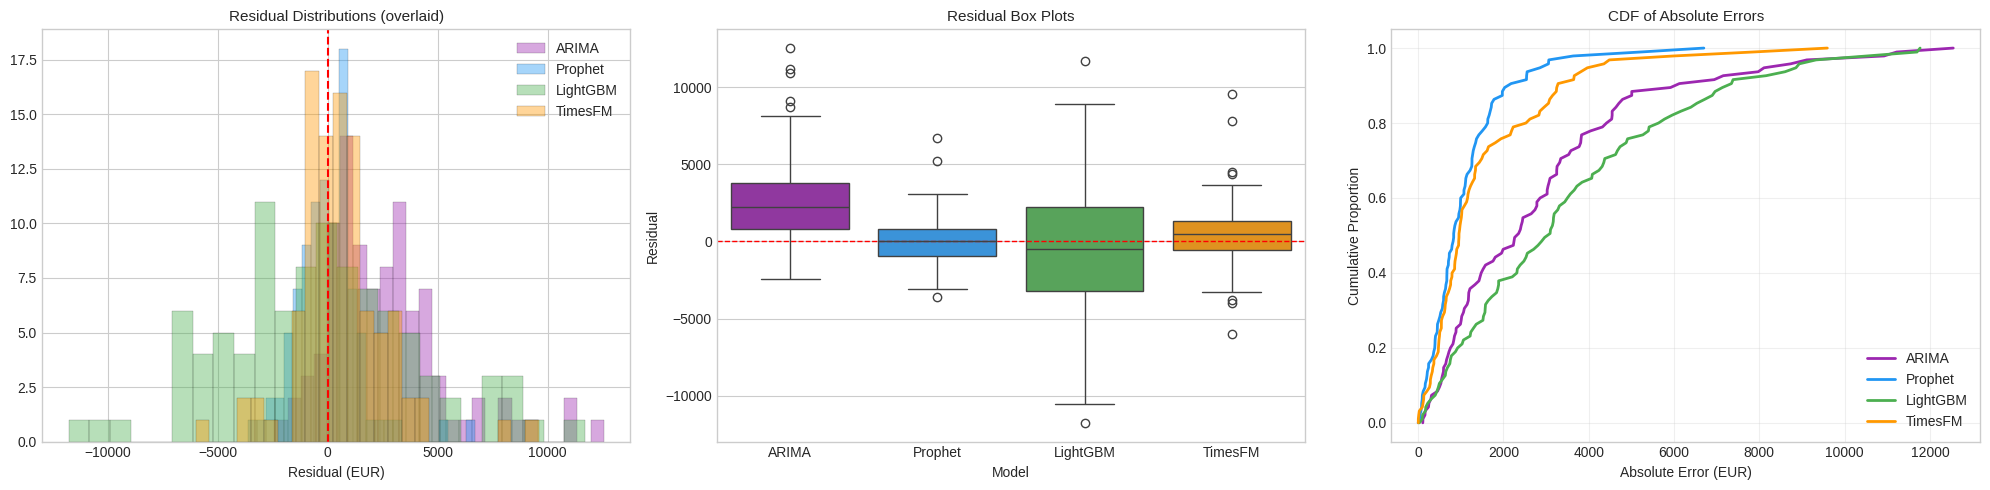

Residual comparison saved.


In [8]:
# Cell 8: Residual distributions — overlaid histograms + box plots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Overlaid histograms
for model_name, resid in all_residuals.items():
    axes[0].hist(resid, bins=25, alpha=0.4, label=model_name,
                 color=MODEL_COLORS[model_name], edgecolor='black',
                 linewidth=0.3)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residual Distributions (overlaid)', fontsize=11)
axes[0].set_xlabel('Residual (EUR)')
axes[0].legend()

# Box plots
resid_df = pd.DataFrame({
    'Residual': np.concatenate(list(all_residuals.values())),
    'Model': np.concatenate([[m]*len(r) for m, r in all_residuals.items()])
})
sns.boxplot(data=resid_df, x='Model', y='Residual', ax=axes[1],
            palette=MODEL_COLORS, order=list(results.keys()))
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('Residual Box Plots', fontsize=11)

# CDF of absolute errors
for model_name, resid in all_residuals.items():
    abs_err = np.sort(np.abs(resid))
    axes[2].plot(abs_err, np.linspace(0, 1, len(abs_err)),
                linewidth=2, label=model_name,
                color=MODEL_COLORS[model_name])
axes[2].set_xlabel('Absolute Error (EUR)')
axes[2].set_ylabel('Cumulative Proportion')
axes[2].set_title('CDF of Absolute Errors', fontsize=11)
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_residuals.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Residual comparison saved.')

## Speed & efficiency

Training/inference time across all four paradigms.


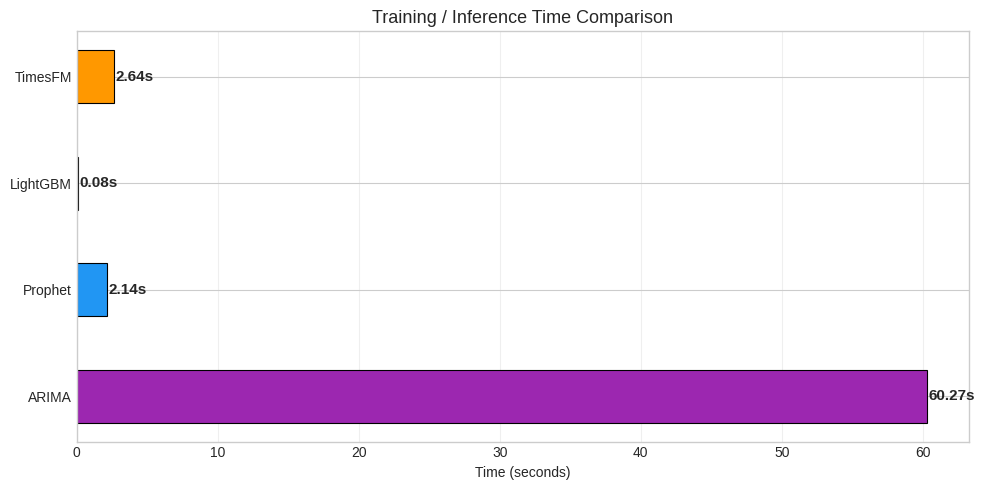


--- Speed Summary ---
  Fastest: LightGBM (0.08s)
  Slowest: ARIMA (60.27s)
  Speed ratio: 753.4x


In [9]:
# Cell 9: Speed comparison
fig, ax = plt.subplots(figsize=(10, 5))

model_names = list(results.keys())
times = [results[m]['training']['total_time_seconds'] for m in model_names]
colors = [MODEL_COLORS[m] for m in model_names]

bars = ax.barh(model_names, times, color=colors, edgecolor='black',
               linewidth=0.8, height=0.5)
for bar, val in zip(bars, times):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}s', ha='left', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Time (seconds)')
ax.set_title('Training / Inference Time Comparison', fontsize=13)
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_speed.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('\n--- Speed Summary ---')
fastest = model_names[np.argmin(times)]
slowest = model_names[np.argmax(times)]
print(f'  Fastest: {fastest} ({min(times):.2f}s)')
print(f'  Slowest: {slowest} ({max(times):.2f}s)')
print(f'  Speed ratio: {max(times)/min(times):.1f}x')

## Ranking the models across multiple dimensions


In [10]:
# Cell 10: Multi-dimensional ranking
# Rank each model per metric (1=best, 4=worst)
rank_df = comparison_df.rank(axis=0, method='min').astype(int)
rank_df['Avg Rank'] = rank_df.mean(axis=1).round(2)
rank_df = rank_df.sort_values('Avg Rank')

print('=== Model Rankings (1=best, 4=worst) ===')
print(rank_df.to_string())
print(f'\nOverall Winner (lowest avg rank): {rank_df.index[0]}')

=== Model Rankings (1=best, 4=worst) ===
          MAE (EUR)  RMSE (EUR)  MAPE (%)  SMAPE (%)  Time (s)  Avg Rank
Model                                                                   
Prophet           1           1         1          1         2       1.2
TimesFM           2           2         2          2         3       2.2
ARIMA             3           3         3          3         4       3.2
LightGBM          4           4         4          4         1       3.4

Overall Winner (lowest avg rank): Prophet


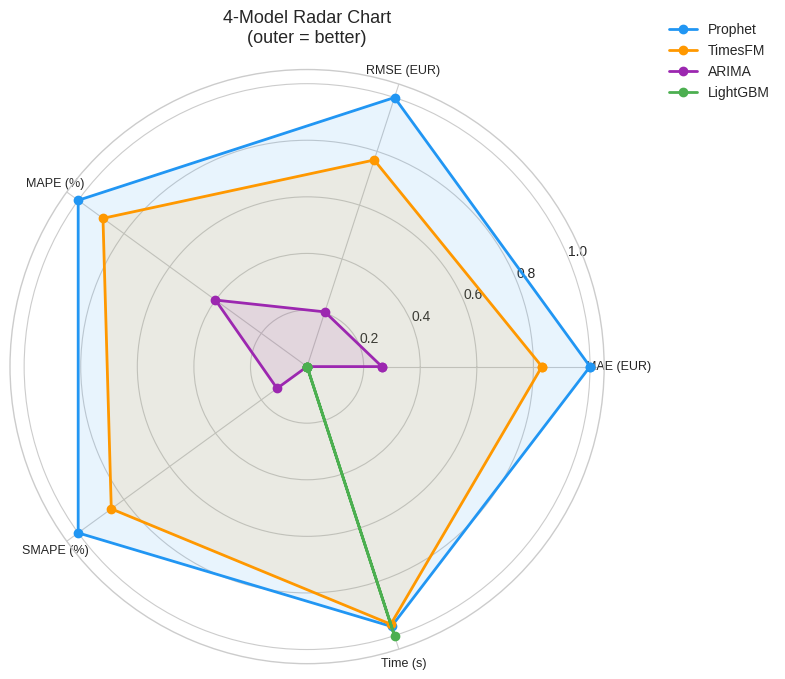

Radar chart saved.


In [11]:
# Cell 11: Radar/spider chart for multi-dimensional comparison
from matplotlib.patches import FancyBboxPatch

# Normalize metrics to 0-1 scale (inverted: lower original = higher score)
norm_df = comparison_df.copy()
for col in norm_df.columns:
    min_val = norm_df[col].min()
    max_val = norm_df[col].max()
    if max_val > min_val:
        norm_df[col] = 1 - (norm_df[col] - min_val) / (max_val - min_val)
    else:
        norm_df[col] = 1.0

# Radar chart
categories = list(norm_df.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for model_name in norm_df.index:
    values = norm_df.loc[model_name].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=model_name,
            color=MODEL_COLORS[model_name])
    ax.fill(angles, values, alpha=0.1, color=MODEL_COLORS[model_name])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9)
ax.set_title('4-Model Radar Chart\n(outer = better)', fontsize=13, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_4model_radar.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Radar chart saved.')

### Model trade-offs

| Model | Paradigm | Regressors | Training | Best For |
|-------|----------|:----------:|:--------:|----------|
| ARIMA | Classical statistical | None | Per-country | Baseline, stationary data |
| Prophet | Modern statistical | Yes (2) | Per-country | Domain knowledge available |
| LightGBM | ML ensemble | Yes (2 + lags) | Global | Feature-rich, fast inference |
| TimesFM | Foundation model | None | Zero-shot | No config, scalability |

### Picking the right one for the job

| Scenario | Recommended Model |
|----------|------------------|
| Need a quick baseline with no setup | ARIMA |
| Have promotional calendars + domain expertise | Prophet |
| Rich feature engineering possible + many series | LightGBM |
| Cold-start / no history / rapid POC | TimesFM |
| Accuracy is paramount, resources available | Prophet or LightGBM |
| Scale to 1000+ series with minimal effort | TimesFM |
| Regulatory explainability required | Prophet (components) or LightGBM (SHAP) |


## Exporting the comparison report


In [ ]:
# Cell 12: Export comparison report JSON
comparison_report = {
    'report_name': '4-Model Sales Forecasting Comparison',
    'timestamp': datetime.now().isoformat(),
    'models': list(results.keys()),
    'study_context': {
        'domain': 'Omnichannel Sales (8 EU countries)',
        'data_period': results['Prophet']['dataset']['date_range'],
        'forecast_horizon': '12 weeks',
        'total_test_points': len(countries) * 12,
        'countries': countries,
    },
    'model_descriptions': {
        'ARIMA': {
            'type': 'Classical statistical',
            'approach': 'Auto-ARIMA per country (AIC)',
            'regressors': None,
        },
        'Prophet': {
            'type': 'Modern statistical (decomposition)',
            'approach': 'Per-country with regressors',
            'regressors': ['promotion_flag', 'covid_period_flag'],
        },
        'LightGBM': {
            'type': 'ML ensemble (gradient boosting)',
            'approach': 'Global model + recursive forecast',
            'regressors': ['promotion_flag', 'covid_period_flag',
                           'lag_1..12', 'rolling stats', 'calendar'],
        },
        'TimesFM': {
            'type': 'Foundation model (Transformer)',
            'approach': 'Zero-shot (no fine-tuning)',
            'regressors': None,
        },
    },
    'overall_metrics': {
        model: results[model]['metrics']['overall']
        for model in results
    },
    'per_country_metrics': {
        model: results[model]['metrics']['per_country']
        for model in results
    },
    'timing': {
        model: results[model]['training']['total_time_seconds']
        for model in results
    },
    'rankings': rank_df.to_dict(),
    'winner_analysis': {
        'overall_mae_winner': comparison_df['MAE (EUR)'].idxmin(),
        'overall_mape_winner': comparison_df['MAPE (%)'].idxmin(),
        'overall_rmse_winner': comparison_df['RMSE (EUR)'].idxmin(),
        'speed_winner': comparison_df['Time (s)'].idxmin(),
        'avg_rank_winner': rank_df.index[0],
        'per_country_mae_wins': dict(country_df['MAE Winner'].value_counts()),
    },
    'residual_stats': {
        model: {
            'mean': float(np.mean(all_residuals[model])),
            'std': float(np.std(all_residuals[model])),
            'median': float(np.median(all_residuals[model])),
        }
        for model in results
    },
}

report_path = f'{RESULTS_DIR}/comparison_4model_report.json'
with open(report_path, 'w') as f:
    json.dump(comparison_report, f, indent=2, default=str)

print(f'Report saved to {report_path}')
print(f'\nArtifacts in {RESULTS_DIR}/:')
for fn in sorted(os.listdir(RESULTS_DIR)):
    print(f'  - {fn}')

Report saved to /content/drive/MyDrive/ML_Prediction_Analysis/Comparison_Results_4Model/comparison_4model_report.json

Artifacts in /content/drive/MyDrive/ML_Prediction_Analysis/Comparison_Results_4Model/:
  - comparison_4model_forecast_overlay.png
  - comparison_4model_metrics.png
  - comparison_4model_per_country.png
  - comparison_4model_radar.png
  - comparison_4model_report.json
  - comparison_4model_residuals.png
  - comparison_4model_speed.png


In [13]:
# Cell 13: Final summary
print('\n' + '=' * 75)
print('FINAL 4-MODEL COMPARISON SUMMARY')
print('=' * 75)
print(f'\n{comparison_df.sort_values("MAE (EUR)").round(2).to_string()}')
print(f'\n--- Rankings (avg rank, lower = better) ---')
for model in rank_df.index:
    print(f'  {model}: {rank_df.loc[model, "Avg Rank"]}')

print(f'\n--- Key Findings ---')
winner = rank_df.index[0]
print(f'  1. Overall winner (by avg rank): {winner}')
print(f'  2. MAE winner: {comparison_df["MAE (EUR)"].idxmin()}')
print(f'  3. Speed winner: {comparison_df["Time (s)"].idxmin()}')
print(f'  4. Per-country wins: {dict(country_df["MAE Winner"].value_counts())}')
print(f'\n--- Evolution of Forecasting ---')
print(f'  Classical (ARIMA) → Modern Statistical (Prophet) →')
print(f'  ML Ensemble (LightGBM) → Foundation Model (TimesFM)')
print(f'\n  Each paradigm offers distinct trade-offs between')
print(f'  accuracy, interpretability, configuration effort, and scalability.')
print('=' * 75)


FINAL 4-MODEL COMPARISON SUMMARY

          MAE (EUR)  RMSE (EUR)  MAPE (%)  SMAPE (%)  Time (s)
Model                                                         
Prophet     1092.77     1507.09      7.40       7.30      2.14
TimesFM     1496.45     2185.28      9.11       9.29      2.64
ARIMA       2840.43     3833.99     16.90      19.27     60.27
LightGBM    3468.40     4427.93     23.24      21.08      0.08

--- Rankings (avg rank, lower = better) ---
  Prophet: 1.2
  TimesFM: 2.2
  ARIMA: 3.2
  LightGBM: 3.4

--- Key Findings ---
  1. Overall winner (by avg rank): Prophet
  2. MAE winner: Prophet
  3. Speed winner: LightGBM
  4. Per-country wins: {'Prophet': np.int64(6), 'TimesFM': np.int64(2)}

--- Evolution of Forecasting ---
  Classical (ARIMA) → Modern Statistical (Prophet) →
  ML Ensemble (LightGBM) → Foundation Model (TimesFM)

  Each paradigm offers distinct trade-offs between
  accuracy, interpretability, configuration effort, and scalability.


---

## Summary

This notebook compared four forecasting paradigms on the company's omnichannel sales data:

1. **ARIMA** — classical baseline, no regressors, fitted per country
2. **Prophet** — statistical decomposition with domain regressors
3. **LightGBM** — feature-engineered ML ensemble, trained as one global model
4. **TimesFM** — zero-shot transformer foundation model

The clearest pattern across all four: domain knowledge (the regressors Prophet and LightGBM use) consistently improves accuracy, but TimesFM's zero-configuration approach is a genuinely compelling option when you need to deploy fast or handle a cold start with no history.
